# E23CSEU0388_Assignment-7


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

from scikeras.wrappers import KerasClassifier

import warnings
warnings.filterwarnings("ignore")

## Task 1: Data Acquisition and Loading


In [2]:
import os

local_candidates = [
    "diabetes.csv",
    "pima-indians-diabetes.csv",
    "Pima Indians Diabetes.csv",
    "pima_diabetes.csv"
]

data = None

for file_name in local_candidates:
    if os.path.exists(file_name):
        data = pd.read_csv(file_name)
        print(f"Loaded local file: {file_name}")
        break

if data is None:
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    columns = [
        "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
    ]
    data = pd.read_csv(url, names=columns)
    print("Dataset downloaded from the public dataset repository.")

print("Shape:", data.shape)
display(data.head())

Loaded local file: diabetes.csv
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Basic dataset inspection

print("Dataset information:")
data.info()

print("\nMissing values:")
display(data.isnull().sum())

print("\nClass distribution:")
display(data["Outcome"].value_counts())

print("\nStatistical summary:")
display(data.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Class distribution:


Outcome
0    500
1    268
Name: count, dtype: int64


Statistical summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## Task 2: Data Preprocessing

The Pima dataset uses zero values in several medical measurement columns where zero is physiologically unrealistic. These values are treated as missing and replaced using the median of the corresponding column.

The target variable is `Outcome`:
- 0 = non-diabetic
- 1 = diabetic

The data is then split into training and testing sets. StandardScaler is used inside the model pipeline so that scaling is learned only from each training fold during cross-validation.

In [4]:
# Replace physiologically impossible zero values with NaN
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

data_clean = data.copy()
data_clean[zero_as_missing] = data_clean[zero_as_missing].replace(0, np.nan)

# Fill missing values with column medians
for column in zero_as_missing:
    data_clean[column] = data_clean[column].fillna(data_clean[column].median())

print("Missing values after preprocessing:")
display(data_clean.isnull().sum())

display(data_clean.head())

Missing values after preprocessing:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [5]:
# Separate features and target
X = data_clean.drop("Outcome", axis=1)
y = data_clean["Outcome"].astype(int)

# Stratified split preserves the class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))
print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

Training set: (614, 8)
Testing set : (154, 8)

Training class distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing class distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


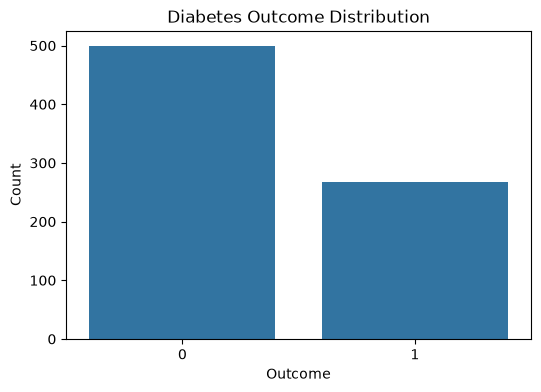

In [6]:
# Visualize the target distribution

plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

# Task 3: Deep Learning Grid Search

A Keras binary-classification model is wrapped using `KerasClassifier` from SciKeras so that it can be used with Scikit-learn's `GridSearchCV`.

The grid includes all parameters requested in the assignment:
- batch size
- training epochs
- learning rate
- network weight initialization
- activation function
- dropout regularization
- number of hidden-layer neurons

A pipeline is used with `StandardScaler` to prevent data leakage during cross-validation.

In [7]:
def create_model(
    neurons=16,
    activation="relu",
    dropout_rate=0.0,
    learning_rate=0.001,
    kernel_initializer="glorot_uniform"
):
    model = Sequential([
        Dense(
            neurons,
            input_shape=(X_train.shape[1],),
            activation=activation,
            kernel_initializer=kernel_initializer
        ),
        Dropout(dropout_rate),
        Dense(
            1,
            activation="sigmoid",
            kernel_initializer=kernel_initializer
        )
    ])

    optimizer = Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Test model creation
test_model = create_model()
test_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Wrap Keras model for Scikit-learn

keras_classifier = KerasClassifier(
    model=create_model,
    verbose=0,
    random_state=42
)

# Pipeline: scaling happens separately inside every CV training fold
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", keras_classifier)
])

print("Scikit-learn pipeline created successfully.")

Scikit-learn pipeline created successfully.


## Grid Search Parameter Space

The following grid is intentionally kept moderate so that the assignment can run on a normal laptop. GridSearchCV evaluates every combination using 3-fold stratified cross-validation.


In [9]:
# Hyperparameter grid

param_grid = {
    "classifier__batch_size": [16, 32],
    "classifier__epochs": [30, 50],
    "classifier__model__learning_rate": [0.001, 0.01],
    "classifier__model__kernel_initializer": [
        "glorot_uniform",
        "he_uniform"
    ],
    "classifier__model__activation": [
        "relu",
        "tanh"
    ],
    "classifier__model__dropout_rate": [
        0.0,
        0.2
    ],
    "classifier__model__neurons": [
        16,
        32
    ]
}

# Total combinations
from itertools import product

n_combinations = np.prod([
    len(values) for values in param_grid.values()
])

print("Total hyperparameter combinations:", int(n_combinations))
print("With 3-fold CV, approximate model fits:", int(n_combinations * 3))

Total hyperparameter combinations: 128
With 3-fold CV, approximate model fits: 384


In [10]:
# GridSearchCV

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,       # safer for TensorFlow on Windows
    verbose=1,
    refit=True,
    return_train_score=True
)

print("Starting Grid Search...")
print("This may take some time because many neural networks are trained.")

grid_search.fit(X_train, y_train)

print("\nGrid Search completed.")

Starting Grid Search...
This may take some time because many neural networks are trained.
Fitting 3 folds for each of 128 candidates, totalling 384 fits

Grid Search completed.


In [12]:
print("Best Cross-Validation Accuracy:")
print(f"{grid_search.best_score_:.4f}")

print("\nBest Hyperparameters:")
for parameter, value in grid_search.best_params_.items():
    print(f"{parameter}: {value}")

Best Cross-Validation Accuracy:
0.7980

Best Hyperparameters:
classifier__batch_size: 32
classifier__epochs: 50
classifier__model__activation: tanh
classifier__model__dropout_rate: 0.2
classifier__model__kernel_initializer: he_uniform
classifier__model__learning_rate: 0.001
classifier__model__neurons: 32


In [13]:
# Display top grid-search results

results = pd.DataFrame(grid_search.cv_results_)

top_results = (
    results[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "param_classifier__batch_size",
            "param_classifier__epochs",
            "param_classifier__model__learning_rate",
            "param_classifier__model__kernel_initializer",
            "param_classifier__model__activation",
            "param_classifier__model__dropout_rate",
            "param_classifier__model__neurons"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

display(top_results)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_classifier__batch_size,param_classifier__epochs,param_classifier__model__learning_rate,param_classifier__model__kernel_initializer,param_classifier__model__activation,param_classifier__model__dropout_rate,param_classifier__model__neurons
125,1,0.798031,0.018976,0.801300,32,50,0.001,he_uniform,tanh,0.2,32
17,2,0.793153,0.020108,0.798046,16,30,0.001,glorot_uniform,tanh,0.0,32
29,3,0.791535,0.012087,0.799674,16,30,0.001,he_uniform,tanh,0.2,32
57,4,0.789901,0.019920,0.801304,16,50,0.001,glorot_uniform,tanh,0.2,32
61,5,0.789893,0.018352,0.807814,16,50,0.001,he_uniform,tanh,0.2,32
93,6,0.788283,0.016457,0.792347,32,30,0.001,he_uniform,tanh,0.2,32
25,7,0.788275,0.017935,0.798044,16,30,0.001,glorot_uniform,tanh,0.2,32
113,8,0.788267,0.012271,0.798046,32,50,0.001,glorot_uniform,tanh,0.0,32
1,9,0.786649,0.019997,0.803753,16,30,0.001,glorot_uniform,relu,0.0,32
121,10,0.786641,0.017998,0.799676,32,50,0.001,glorot_uniform,tanh,0.2,32


## Evaluate the Best Model on the Test Set

The best estimator selected by GridSearchCV is already refitted on the complete training data because `refit=True` was used.

In [14]:
# Test-set evaluation

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
y_pred = np.asarray(y_pred).astype(int).ravel()

test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Non-Diabetic", "Diabetic"]
    )
)

Test Accuracy: 0.7273

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.79      0.79      0.79       100
    Diabetic       0.61      0.61      0.61        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



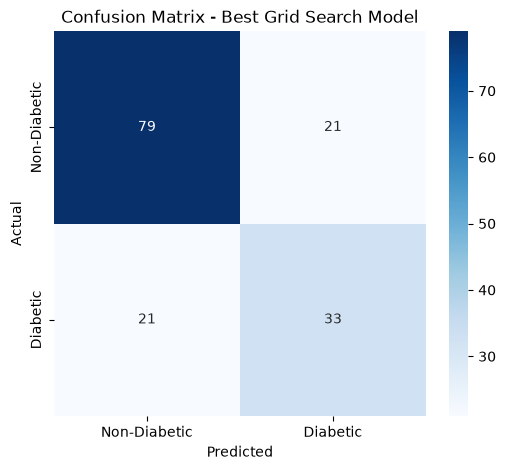

In [15]:
# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Diabetic", "Diabetic"],
    yticklabels=["Non-Diabetic", "Diabetic"]
)
plt.title("Confusion Matrix - Best Grid Search Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Final Results

The GridSearchCV process identifies the combination of hyperparameters that produces the highest mean cross-validation accuracy.

The final test accuracy is calculated separately on the held-out test set. This gives an unbiased estimate of how the selected deep-learning model performs on unseen data.
